<a href="https://colab.research.google.com/github/LKM07/data-science-toolkit/blob/main/Tutorial_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

------------Tutorial 03-------------------

#Tidy Data, Data Characteristics

1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

,timestamp,device,usage_category,prompt_length,session_length_minutes,satisfaction_rating,assistant_model,tokens_used
0,2025-02-20 03:29:00,Desktop,Education,14,7.08,5,GPT-5.1,44
1,2025-01-08 18:28:00,Mobile,Daily Tasks,32,13.07,2,GPT-4o,1047
2,2025-01-12 17:56:00,Smart Speaker,Education,236,10.15,4,GPT-4o,1379
3,2025-01-04 09:11:00,Smart Speaker,Productivity,98,14.45,1,GPT-5,1105
4,2025-02-14 19:59:00,Smart Speaker,Research,220,4.50,5,GPT-5.1,107


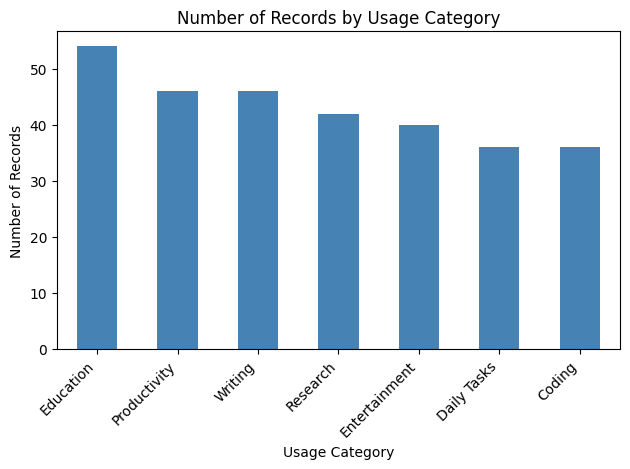

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = "/content/Daily_AI_Assistant_Usage_Behavior_Dataset.csv"

df = pd.read_csv(file_path, parse_dates=["timestamp"])

display(df.head())

category_counts = df["usage_category"].value_counts()

category_counts.plot(kind="bar", color="steelblue")
plt.title("Number of Records by Usage Category")
plt.xlabel("Usage Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

2. Evaluate if the data is good or not. Does it have enough samples?

In [2]:
print("Rows and columns:", df.shape)
print("Fully duplicated rows:", df.duplicated().sum())
print("\nRecords per usage category:")
print(df["usage_category"].value_counts())

Rows and columns: (300, 8)
Fully duplicated rows: 0

Records per usage category:
usage_category
Education        54
Productivity     46
Writing          46
Research         42
Entertainment    40
Daily Tasks      36
Coding           36
Name: count, dtype: int64


3. How many features does it have? Is it enough?

In [10]:
target = "tokens_used"
feature_columns = [column for column in df.columns if column != target]

print("Number of features:", len(feature_columns))
print("Features:", feature_columns)

Number of features: 7
Features: ['timestamp', 'device', 'usage_category', 'prompt_length', 'session_length_minutes', 'satisfaction_rating', 'assistant_model']


4. How many samples/observation does it have? Is it enough?

In [4]:
print("Number of samples:", len(df))

Number of samples: 300


5. What are the datatypes does the dataset consist of?

In [5]:
print(df.dtypes)

timestamp                 datetime64[ns]
device                            object
usage_category                    object
prompt_length                      int64
session_length_minutes           float64
satisfaction_rating                int64
assistant_model                   object
tokens_used                        int64
dtype: object


6. How many columns have null values? If yes, which column, which rows

In [6]:
missing_by_column = df.isna().sum()

print("Missing values in each column:")
print(missing_by_column)

columns_with_missing = missing_by_column[missing_by_column > 0]

print("\nNumber of columns with missing values:", len(columns_with_missing))
print("Columns with missing values:")
print(columns_with_missing)

Missing values in each column:
timestamp                 0
device                    0
usage_category            0
prompt_length             0
session_length_minutes    0
satisfaction_rating       0
assistant_model           0
tokens_used               0
dtype: int64

Number of columns with missing values: 0
Columns with missing values:
Series([], dtype: int64)


7. Which column is the feature, which is the target output?

In [15]:
target = "tokens_used"
X = df.drop(columns=[target])
y = df[target]

print("Target:", target)
print("Feature columns:", X.columns.tolist())
print("Target values:", sorted(y.unique()))

Target: tokens_used
Feature columns: ['timestamp', 'device', 'usage_category', 'prompt_length', 'session_length_minutes', 'satisfaction_rating', 'assistant_model']
Target values: [np.int64(32), np.int64(39), np.int64(44), np.int64(49), np.int64(52), np.int64(53), np.int64(55), np.int64(67), np.int64(77), np.int64(80), np.int64(84), np.int64(85), np.int64(89), np.int64(93), np.int64(95), np.int64(100), np.int64(104), np.int64(105), np.int64(107), np.int64(115), np.int64(119), np.int64(125), np.int64(140), np.int64(147), np.int64(152), np.int64(169), np.int64(181), np.int64(188), np.int64(202), np.int64(223), np.int64(229), np.int64(234), np.int64(239), np.int64(241), np.int64(242), np.int64(243), np.int64(245), np.int64(250), np.int64(267), np.int64(276), np.int64(278), np.int64(280), np.int64(284), np.int64(286), np.int64(292), np.int64(296), np.int64(298), np.int64(300), np.int64(301), np.int64(309), np.int64(310), np.int64(312), np.int64(321), np.int64(327), np.int64(330), np.int64(3

8. Does it have missing values? If yes, which column, which row.

In [8]:
rows_missing = df[df.isna().any(axis=1)]

if rows_missing.empty:
    print("There are no rows with missing values.")
else:
    for index, row in rows_missing.iterrows():
        missing_columns = row.index[row.isna()].tolist()
        print(
            f"DataFrame index {index} "
            f"(CSV row {index + 2}) has missing values in: {missing_columns}"
        )

    display(rows_missing)

There are no rows with missing values.


9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

Question: How does the distribution of token usage vary across usage categories?

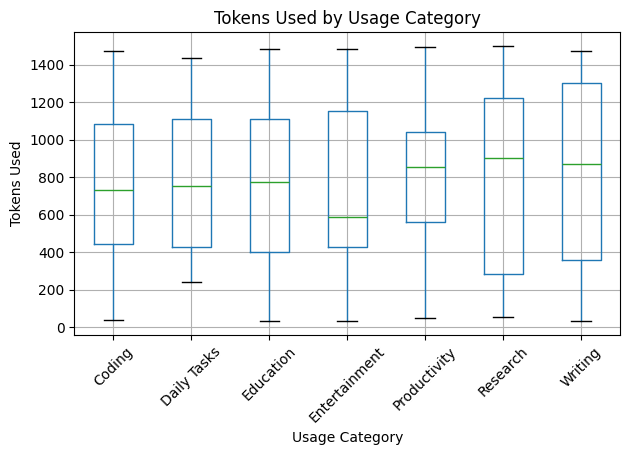

                count        mean  median
usage_category                           
Coding             36  753.916667   729.5
Daily Tasks        36  805.222222   753.0
Education          54  746.111111   774.5
Entertainment      40  739.475000   589.0
Productivity       46  800.369565   855.5
Research           42  787.119048   902.0
Writing            46  832.326087   870.5


In [12]:
df.boxplot(column="tokens_used", by="usage_category", rot=45)
plt.title("Tokens Used by Usage Category")
plt.suptitle("")
plt.xlabel("Usage Category")
plt.ylabel("Tokens Used")
plt.tight_layout()
plt.show()

print(
    df.groupby("usage_category")["tokens_used"]
      .agg(["count", "mean", "median"])
)